# 0.x에서 1.x로 마이그레이션

**이 노트북에서 할 일**

1. 옛 판의 에이전트 함수 `create_react_agent`와 지금 판 `create_agent`가 받는 인자 이름을 견줍니다.
2. 같은 모델·도구·시스템 메시지 글로 두 함수가 만든 그래프의 노드·엣지·칸을 견줍니다.
3. 양식 클래스를 더 넘겨, 옛 함수의 그래프에만 더해지는 노드를 봅니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
키는 모델 객체를 만들 때 읽습니다.
이 노트북은 그래프를 만들기만 하고 실행하지 않아, 모델 요청을 한 번도 보내지 않습니다.
그래서 요금표로 어림한 예상 비용도 0달러입니다.
도구도 실행하지 않고, 자료 파일을 읽거나 새로 쓰지 않습니다.

앞에서 배운 함수 하나는 도구 파일 `runner_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 5초 안에 끝났습니다.
설치 셀에 걸리는 시간은 네트워크에 따라 달라집니다.

**0.x 판에 대해** — 0.x는 판 번호 앞자리가 0인 옛 판들이고, 1.x는 앞자리가 1인 지금 판들입니다.
실습 폴더의 잠금 파일(`uv.lock`)에는 0.x 판이 없어, 이 노트북은 0.x 판을 실행하지 않습니다.
대신 지금 판에 경고와 함께 남아 있는 옛 함수로 그래프 모양만 견줍니다.
옛 함수는 langgraph를 설치할 때 함께 들어오는 langgraph-prebuilt 1.1.0에 들어 있습니다.

**기준 버전** — 첫 셀에서 패키지 여덟을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
langgraph 1.2.11과 langgraph-prebuilt 1.1.0도 함께 설치합니다.
numpy 2.5.3, pydantic 2.13.5, python-dotenv 1.2.3도 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었고, 다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~5절을 읽습니다.
두 함수가 받는 인자와, 옛 함수를 부를 때 나오는 경고를 보는 자리입니다.
6~8절은 두 그래프의 노드·엣지·칸을 견주고 값 하나를 바꿔 보는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch21-create-agent`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위아래 칸 둘이 있는 그림으로 위 칸 옛 함수 create_react_agent 인자 prompt에는 회색 상자 agent와 tools와 끝점 __end__가 있고 agent에서 tools와 __end__로 should_continue 점선이, tools에서 agent로 고정 엣지 실선이 갑니다. 노란 상자에는 받은 경고 하나 고정 엣지 둘 시작점 엣지 포함이 적혀 있습니다. 아래 칸 새 함수 create_agent 인자 system_prompt에는 회색 상자 model과 tools와 __end__가 있고 model에서 tools와 __end__로 model_to_tools 점선이, tools에서 model로 tools_to_model 점선이 갑니다. 노란 상자에는 받은 경고 없음 고정 엣지 하나 시작점 엣지가 적혀 있는 그림](attachment:04-1-두-함수가-만든-그래프.png)

위 칸이 옛 함수, 아래 칸이 새 함수가 만든 그래프입니다.
회색 상자는 라이브러리가 만든 노드이고, 노란 상자는 노트북 5·6절에서 출력한 값입니다.
가상 시작점은 두 그래프 모두 첫 노드로 가는 실선 하나라 그리지 않았습니다.
두 칸의 차이는 모델 노드 이름과, tools에서 돌아오는 화살표의 모양입니다.
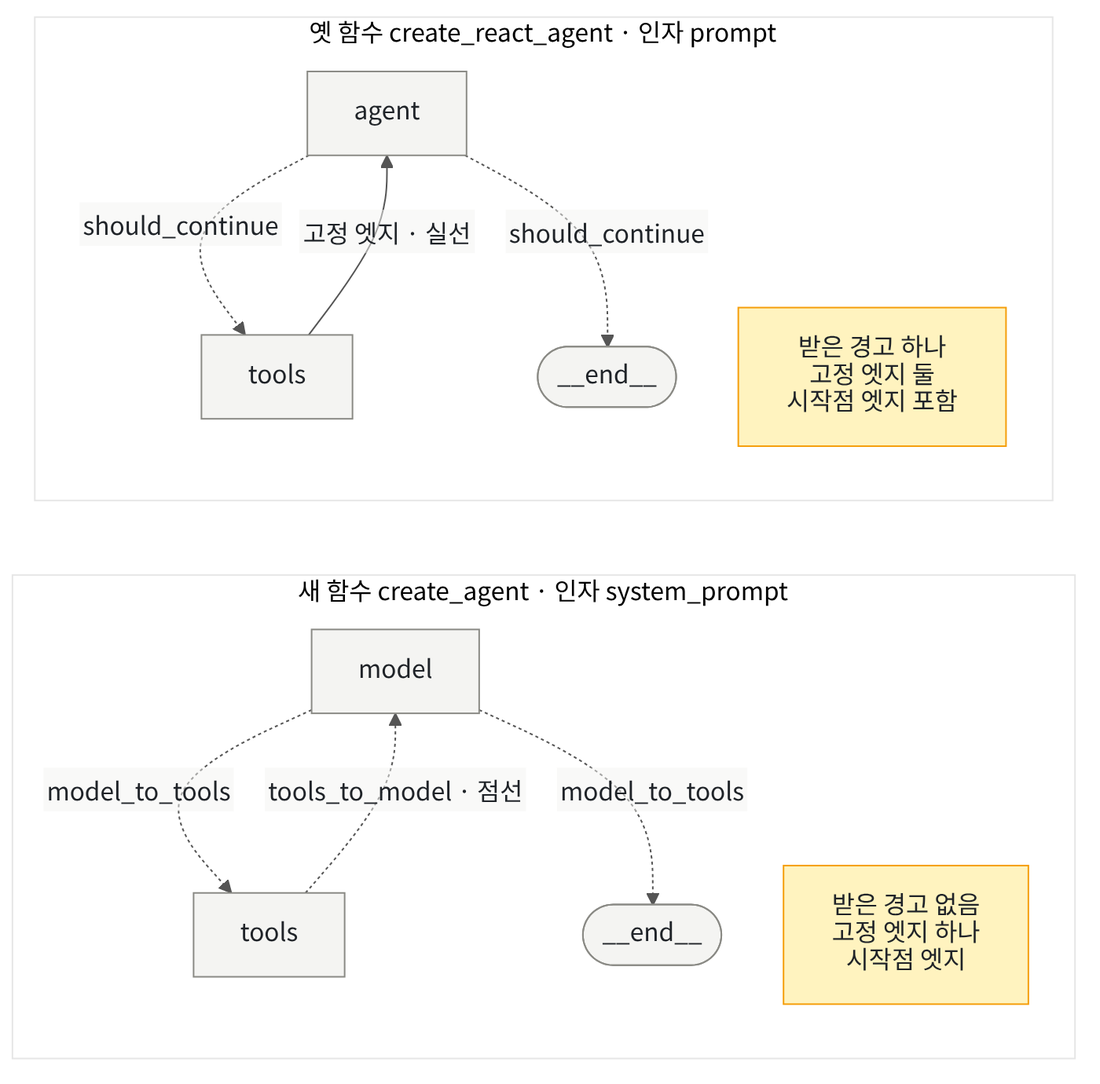

## 1. 준비

01~03절에서는 함수 `create_agent`로 에이전트 그래프를 만들었습니다.
이 함수가 나오기 전 판에서는 LangGraph의 함수 `create_react_agent`로 같은 일을 했습니다.
제목의 마이그레이션(migration)은 옛 판에서 쓴 코드를 새 판에서 돌도록 고쳐 쓰는 일입니다.
이 절은 두 함수로 같은 그래프를 만들어, 옮길 때 무엇을 고쳐야 하는지 출력으로 봅니다.

첫 셀은 패키지 여덟 개를 설치하고 설치된 판 번호를 출력합니다.
도구 파일이 NumPy를 쓰므로, 01절처럼 numpy도 함께 설치합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "langgraph==1.2.11" "langgraph-prebuilt==1.1.0" "numpy==2.5.3" "pydantic==2.13.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("langgraph-prebuilt:", version("langgraph-prebuilt"))
print("numpy:", version("numpy"))
print("pydantic:", version("pydantic"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langgraph: 1.2.11
langgraph-prebuilt: 1.1.0
numpy: 2.5.3
pydantic: 2.13.5
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`langchain-openai: 1.6.0`이 보입니다.
출력 줄 `langgraph: 1.2.11`·`langgraph-prebuilt: 1.1.0`도 잠금과 같은 판입니다.
출력 줄 `numpy: 2.5.3`·`pydantic: 2.13.5`·`python-dotenv: 1.2.3`도 같습니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `inspect`와 `warnings`는 Python에 들어 있는 기능 묶음입니다.
모듈 `inspect`로 함수가 받는 인자 이름을 읽고, `warnings`로 경고를 모읍니다.
함수 `create_react_agent`는 모듈 `langgraph.prebuilt`에서 가져오는 옛 함수입니다.
양식 클래스를 적을 이름 `BaseModel`·`Field`·`Literal`은 02절과 같습니다.

In [2]:
# 두 함수와, 인자 목록을 읽을 모듈·경고를 모을 모듈, 01·02절에서 쓴 이름을 가져옵니다
import inspect
import warnings
from typing import Literal

from pydantic import BaseModel, Field
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langgraph.prebuilt import create_react_agent

# 앞에서 배운 함수는 도구 파일에서 가져옵니다
from runner_tools import print_branches

print("이 절에서 새로 가져온 이름:", "inspect", "warnings", "create_react_agent")

이 절에서 새로 가져온 이름: inspect warnings create_react_agent


**결과 읽기** — 출력 줄 `이 절에서 새로 가져온 이름: inspect warnings create_react_agent`가 보입니다.
옛 함수를 가져오는 줄에서는 경고가 나오지 않았습니다.

앞에서 배운 함수는 `runner_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

함수 `print_branches`는 02절 6절에서 처음 적고, 03절부터 도구 파일에서 가져오는 함수입니다.
이 절에서는 도구 파일에서 이 함수 하나만 가져옵니다.

## 2. 키와 모델 준비

모델 객체는 01절과 같은 `gpt-5.4-mini`를 과정의 같은 설정으로 만듭니다.
이 절은 모델 객체를 두 함수에 넘겨 그래프를 만들기만 하고, 모델에게 요청을 보내지 않습니다.
그래도 모델 객체를 만들 때 키가 있어야 해서 키 셀을 둡니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델 객체를 준비합니다.
설정은 01절과 같지만, 이 절에서는 요청을 보내지 않아 답 글이 나오지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-25에 실행한 결과이고, 이 모델에게 보낸 요청은 없습니다.

## 3. 규정 자료, 도구, 양식 클래스

두 함수에 같은 재료를 넘기려고, 01절의 규정 딕셔너리와 도구를 다시 만듭니다.
다음 셀은 01절 3절 셀과 글자까지 같은 코드입니다.

In [5]:
# 교육센터 자료실 규정 셋을, 주제어를 키로 한 딕셔너리에 담습니다(도구가 읽기만 하는 자료)
POLICIES = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
}
topics = list(POLICIES.keys())
print("규정 주제어:", topics)

규정 주제어: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '운영', '연체']`로 키 셋을 확인합니다.
이 절에서는 도구를 실행하지 않지만, 01절과 같은 도구를 만들려고 이 딕셔너리를 둡니다.

다음 셀도 01절 3절의 도구 셀과 글자까지 같은 코드입니다.

In [6]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_policy(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 운영, 연체 가운데 하나를 넣습니다."""
    # 딕셔너리에 없는 주제어면 오류를 냅니다(이 오류를 그래프 안에서 다루는 법은 Ch 20 02절에서 보았습니다)
    if topic not in POLICIES:
        raise ValueError("지원하지 않는 주제: " + topic)
    return POLICIES[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 이름은 `lookup_policy`이고, 5절에서 두 함수에 이 도구 하나를 똑같이 넘깁니다.

다음 셀은 02절 4절의 양식 클래스 셀과 글자까지 같은 코드입니다.
8절 값 바꿔 보기에서 두 함수에 이 양식 클래스를 넘깁니다.

In [7]:
# 답을 담을 양식 클래스를 적습니다(칸 둘: 주제어와 한 문장 답)
class PolicyAnswer(BaseModel):
    # 주제어 칸에는 괄호 안 세 값 가운데 하나만 적을 수 있습니다(Ch 19 02절 Literal)
    topic: Literal["대출", "운영", "연체"] = Field(description="답의 근거가 된 규정의 주제어")
    answer: str = Field(description="찾은 규정 글에 근거한 한 문장 답")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
양식 클래스 `PolicyAnswer`의 칸은 `topic`과 `answer` 둘입니다.

## 4. 두 함수가 받는 인자 이름

옛 판 코드를 옮길 때 먼저 보이는 차이는 인자 이름입니다.
함수 `inspect.signature`는 함수 하나를 받아, 그 함수가 받는 인자 목록을 담은 객체를 내놓습니다.
그 객체의 속성 `parameters`를 목록으로 바꾸면 인자 이름만 남습니다.
다음 셀은 두 함수의 인자 이름을 목록으로 모으고, 앞 두 자리를 봅니다.

In [8]:
# 두 함수가 받는 인자 이름을 목록으로 모읍니다(inspect.signature는 함수의 인자 목록을 담은 객체를 내놓음)
old_signature = inspect.signature(create_react_agent)
old_params = list(old_signature.parameters)
new_signature = inspect.signature(create_agent)
new_params = list(new_signature.parameters)
# 목록의 앞 두 자리는 이름 없이 차례로 넘기는 인자입니다
print("옛 함수의 처음 두 인자:", old_params[0:2])
print("새 함수의 처음 두 인자:", new_params[0:2])

옛 함수의 처음 두 인자: ['model', 'tools']
새 함수의 처음 두 인자: ['model', 'tools']


**결과 읽기** — 출력 줄 `옛 함수의 처음 두 인자: ['model', 'tools']`와 `새 함수의 처음 두 인자: ['model', 'tools']`입니다.
두 함수 모두 모델과 도구 목록을 앞 두 자리로 받습니다.
그래서 모델 객체와 도구 목록을 넘기는 부분은 옮길 때 그대로 둘 수 있습니다.

다음 셀은 이 절에서 견줄 인자 이름 여덟을 두 목록에서 찾아봅니다.
연산자 `in`은 값이 목록에 있으면 `True`, 없으면 `False`를 냅니다.

In [9]:
# 이 절에서 견줄 인자 이름마다, 두 함수가 그 인자를 받는지 봅니다
check_names = [
    "prompt", "system_prompt", "pre_model_hook", "post_model_hook",
    "middleware", "response_format", "state_schema", "context_schema",
]
for name in check_names:
    print(name, "| 옛 함수:", name in old_params, "| 새 함수:", name in new_params)

prompt | 옛 함수: True | 새 함수: False
system_prompt | 옛 함수: False | 새 함수: True
pre_model_hook | 옛 함수: True | 새 함수: False
post_model_hook | 옛 함수: True | 새 함수: False
middleware | 옛 함수: False | 새 함수: True
response_format | 옛 함수: True | 새 함수: True
state_schema | 옛 함수: True | 새 함수: True
context_schema | 옛 함수: True | 새 함수: True


**결과 읽기** — 줄 `prompt | 옛 함수: True | 새 함수: False`와 `system_prompt | 옛 함수: False | 새 함수: True`가 짝입니다.
옛 함수는 시스템 메시지 글을 인자 `prompt`로 받았고, 새 함수는 `system_prompt`로 받습니다.
옛 함수의 `pre_model_hook`·`post_model_hook`은 새 함수에 없고, 새 함수에는 `middleware`가 있습니다.
나머지 셋 `response_format`·`state_schema`·`context_schema`는 두 함수 모두 받습니다.

이 출력이 보여 주는 것은 두 함수에 어느 인자 이름이 있는가까지입니다.
LangChain 공식 옮기기 안내는 인자 `prompt`를 `system_prompt`로 바꾸라고 적습니다.
모델 앞뒤 훅은 미들웨어로 옮기라고 적는데, 미들웨어는 Ch 22에서 배웁니다.

## 5. 옛 함수로 그래프 만들기

다음 셀은 옛 함수로 01절과 같은 에이전트 그래프를 만듭니다.
모델 객체와 도구는 같고, 01절 시스템 메시지 글은 인자 `prompt`로 넘깁니다.
옛 함수는 부를 때마다 경고를 하나 냅니다.

노트북 밖에서 확인해 보면, 이 경고는 셀 출력에 실행한 컴퓨터의 임시 파일 위치와 함께 찍혔습니다.
그래서 경고를 목록에 모았다가 필요한 값만 출력합니다.
블록 `with`는 Ch 2 05절에서 파일을 열 때 썼습니다.
여기서는 `warnings.catch_warnings(record=True)`로, 블록 안에서 나온 경고를 목록에 모읍니다.

In [10]:
# 옛 함수로 01절과 같은 에이전트 그래프를 만들고, 그동안 나온 경고를 목록에 모읍니다(요청은 보내지 않음)
system_text = "교육센터 자료실 안내 도우미입니다. 자료실 규정을 묻는 질문에는 lookup_policy 도구로 찾은 규정 글에 근거해 답하세요."
with warnings.catch_warnings(record=True) as old_warnings:
    # 이 블록 안에서는 같은 경고도 빠짐없이 목록에 모읍니다
    warnings.simplefilter("always")
    # 옛 함수는 시스템 메시지 글을 인자 prompt로 받습니다
    old_agent = create_react_agent(model, tools=[lookup_policy], prompt=system_text)
print("만든 것의 종류:", type(old_agent).__name__)
print("받은 경고 수:", len(old_warnings))

만든 것의 종류: CompiledStateGraph
받은 경고 수: 1


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`로, 01절과 같은 종류의 그래프입니다.
출력 줄 `받은 경고 수: 1`로, 옛 함수를 한 번 부르자 경고 하나가 목록에 모였습니다.
이 셀에서도 모델 요청은 나가지 않습니다.

다음 셀은 모은 경고의 종류와 글을 봅니다.
함수 `issubclass`는 앞의 클래스가 뒤의 클래스를 물려받았는지를 참·거짓으로 알려 줍니다.
클래스 `DeprecationWarning`은 곧 없앨 기능을 쓸 때 Python이 내는 경고의 종류입니다.

In [11]:
# 모은 경고의 종류와 글을 봅니다(경고 하나에 종류 category와 글 message가 들어 있음)
first_warning = old_warnings[0]
print("경고 종류:", first_warning.category.__name__)
print("사용 중단 경고의 한 종류인가:", issubclass(first_warning.category, DeprecationWarning))
print("경고 글:")
print(first_warning.message)

경고 종류: LangGraphDeprecatedSinceV10
사용 중단 경고의 한 종류인가: True
경고 글:
create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.


**결과 읽기** — 출력 줄 `경고 종류: LangGraphDeprecatedSinceV10`입니다.
출력 줄 `사용 중단 경고의 한 종류인가: True`로, 사용 중단 경고를 물려받은 종류입니다.
라벨 줄 `경고 글:` 아래 앞부분 `create_react_agent has been moved to`는 함수가 다른 자리로 옮겨졌다는 뜻입니다.
이어서 모듈 `langchain.agents`에서 `create_agent`를 가져오라고 알립니다.

끝 문장 `Deprecated in LangGraph V1.0 to be removed in V2.0.`은 LangGraph 1.0부터 쓰지 말라고 알린(사용 중단을 예고한) 기능이라는 뜻입니다.
경고 글에 따르면 2.0 판에서 없어질 예정입니다.
설치판 소스(`chat_agent_executor.py` 274~277행)로 보면, 함수 위에 붙은 표시가 부를 때마다 이 경고를 냅니다.

다음 셀은 새 함수로 같은 그래프를 만들고, 여기서도 경고를 모읍니다.
새 함수는 같은 시스템 메시지 글을 인자 `system_prompt`로 받습니다.
01절 4절 셀과 인자가 같은 줄이고, 만든 그래프의 이름만 `new_agent`로 바꿨습니다.

In [12]:
# 새 함수로 같은 에이전트 그래프를 만들고, 여기서도 경고를 모읍니다(요청은 보내지 않음)
with warnings.catch_warnings(record=True) as new_warnings:
    warnings.simplefilter("always")
    # 새 함수는 같은 시스템 메시지 글을 인자 system_prompt로 받습니다
    new_agent = create_agent(model, tools=[lookup_policy], system_prompt=system_text)
print("만든 것의 종류:", type(new_agent).__name__)
print("받은 경고 수:", len(new_warnings))

만든 것의 종류: CompiledStateGraph
받은 경고 수: 0


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`로, 옛 함수와 같은 종류입니다.
출력 줄 `받은 경고 수: 0`으로, 새 함수는 경고를 내지 않았습니다.

## 6. 노드와 엣지 견주기

두 그래프는 같은 모델·도구·시스템 메시지 글로 만들었습니다.
다음 셀은 01절 5절처럼 설계 객체의 속성 `nodes`로 등록된 노드를 봅니다.

In [13]:
# 두 그래프의 설계 객체에서 등록된 노드를 봅니다(01절 5절 builder.nodes)
old_nodes = list(old_agent.builder.nodes)
new_nodes = list(new_agent.builder.nodes)
print("옛 그래프의 노드:", old_nodes)
print("새 그래프의 노드:", new_nodes)

옛 그래프의 노드: ['agent', 'tools']
새 그래프의 노드: ['model', 'tools']


**결과 읽기** — 출력 줄 `옛 그래프의 노드: ['agent', 'tools']`와 `새 그래프의 노드: ['model', 'tools']`입니다.
도구 실행 노드의 이름은 `tools`로 같고, 모델 노드의 이름이 `agent`에서 `model`로 바뀌었습니다.
공식 옮기기 안내는 스트리밍으로 받는 노드 이름도 `agent`에서 `model`로 바뀌었다고 적습니다.
스트리밍은 Ch 25에서 배우고, 이번에 실행하지 않았습니다.

다음 셀은 구조 문자열에서 화살표가 든 줄만 골라 출력하는 함수를 적습니다.
01절 5절에서는 구조 문자열 전체를 출력했는데, 이번에는 그래프 넷을 견주므로 엣지 줄만 봅니다.
메서드 `splitlines`는 글을 줄마다 나눈 목록을, `strip`은 앞뒤 빈칸을 뺀 글을 내놓습니다.

In [14]:
# 에이전트 그래프 하나의 구조 문자열에서 화살표가 든 줄만 골라 출력합니다(내놓는 값 없음)
def print_arrow_lines(graph_agent):
    structure_text = graph_agent.get_graph().draw_mermaid()
    for line in structure_text.splitlines():
        # 실선 화살표나 점선 화살표가 든 줄이 엣지이고, 나머지는 상자와 꾸밈 줄입니다
        if "-->" in line or "-.->" in line:
            print(line.strip())

**결과 읽기** — 정의 셀이라 출력이 없습니다.
구조 문자열에서 실선 화살표는 `-->`, 점선 화살표는 `-.->`로 적힙니다.

다음 셀은 이 함수로 두 그래프의 화살표 줄을 봅니다.

In [15]:
# 두 그래프의 화살표 줄을 차례로 봅니다
print("옛 그래프의 화살표 줄:")
print_arrow_lines(old_agent)
print("새 그래프의 화살표 줄:")
print_arrow_lines(new_agent)

옛 그래프의 화살표 줄:
__start__ --> agent;
agent -.-> __end__;
agent -.-> tools;
tools --> agent;
새 그래프의 화살표 줄:
__start__ --> model;
model -.-> __end__;
model -.-> tools;
tools -.-> model;


**결과 읽기** — 라벨 줄 `옛 그래프의 화살표 줄:` 아래 네 줄과 `새 그래프의 화살표 줄:` 아래 네 줄입니다.
되돌아가는 엣지가 옛 그래프는 실선 `tools --> agent;`, 새 그래프는 점선 `tools -.-> model;`입니다.
나머지 세 줄은 노드 이름만 다르고 화살표 모양이 같습니다.

옛 그래프의 네 줄에서 `agent`를 `model`로 바꿔 읽으면, Ch 20 01절 구조 문자열의 화살표 줄과 같습니다.
01절에서 본 것처럼 새 그래프의 되돌아가는 엣지는 조건부 엣지라 점선입니다.

다음 셀은 고정 엣지로 적힌 수와 조건 함수를 봅니다.
조건 함수는 02절 함수 `print_branches`로 봅니다.

In [16]:
# 고정 엣지로 적힌 수와 조건 함수를 봅니다(조건 함수는 02절 함수 print_branches — 도구 파일)
print("옛 그래프의 고정 엣지 수:", len(old_agent.builder.edges))
print_branches(old_agent)
print("새 그래프의 고정 엣지 수:", len(new_agent.builder.edges))
print_branches(new_agent)

옛 그래프의 고정 엣지 수: 2
agent | 조건 함수: should_continue | 갈 수 있는 곳: ['tools', '__end__']
새 그래프의 고정 엣지 수: 1
tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model']
model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__']


**결과 읽기** — 출력 줄 `옛 그래프의 고정 엣지 수: 2`와 `새 그래프의 고정 엣지 수: 1`입니다.
옛 그래프의 조건 함수 줄은 `agent | 조건 함수: should_continue | 갈 수 있는 곳: ['tools', '__end__']` 하나입니다.
새 그래프는 01절과 같이 `tools_to_model`과 `model_to_tools` 두 줄입니다.
옛 그래프에서 되돌아가는 엣지는 조건 함수 없이 고정 엣지로 적혀, 실선으로 그려졌습니다.

설치판 소스(`chat_agent_executor.py` 990행)에도 도구 실행 노드에서 모델 노드로 가는 고정 엣지를 적는 줄이 있습니다.
옛 그래프의 고정 엣지 둘은 가상 시작점에서 오는 엣지와 이 되돌아가는 엣지입니다.

## 7. 상태 칸과 입력 칸 견주기

다음 셀은 두 그래프의 상태 칸을 봅니다.
속성 `managed`에는 그래프가 실행하면서 스스로 채우는 값의 이름이 들어 있습니다.

In [17]:
# 두 그래프의 상태 칸과, 그래프가 실행하면서 스스로 채우는 값(속성 managed)을 봅니다
print("옛 그래프의 상태 칸:", list(old_agent.builder.channels))
print("옛 그래프가 채우는 값:", list(old_agent.builder.managed))
print("새 그래프의 상태 칸:", list(new_agent.builder.channels))
print("새 그래프가 채우는 값:", list(new_agent.builder.managed))

옛 그래프의 상태 칸: ['messages']
옛 그래프가 채우는 값: ['remaining_steps']
새 그래프의 상태 칸: ['messages', 'jump_to', 'structured_response']
새 그래프가 채우는 값: []


**결과 읽기** — 출력 줄 `옛 그래프의 상태 칸: ['messages']`와 `옛 그래프가 채우는 값: ['remaining_steps']`입니다.
출력 줄 `새 그래프의 상태 칸: ['messages', 'jump_to', 'structured_response']`는 01절 5절과 같습니다.
새 그래프가 채우는 값은 빈 목록 `[]`입니다.
옛 그래프의 상태 칸은 메시지 칸 하나이고, 새 그래프에는 03절에서 본 라이브러리 상태 형식의 칸 셋이 있습니다.

설치판 소스(`chat_agent_executor.py` 57~62행)로 보면, 옛 상태 형식에 `remaining_steps`가 적혀 있습니다.
이 값은 Ch 20 03절의 실행 한도까지 남은 단계 수이고, 그래프가 단계마다 채웁니다.
같은 소스 620~633행을 보면, 옛 모델 노드가 이 값을 읽습니다.
남은 단계가 둘보다 적은데 도구 호출 요청이 오면, 도구로 가지 않고 멈추는 글을 남깁니다.
이 동작은 이번에 실행하지 않았습니다.

다음 셀은 두 그래프가 입력으로 받는 칸을 봅니다.
메서드 `get_input_jsonschema`는 그래프의 입력 형식을 JSON 모양 설명으로 내놓습니다.
02절 4절 `model_json_schema`처럼, 칸 이름은 키 `properties` 아래에 있습니다.

In [18]:
# 두 그래프가 입력으로 받는 칸을, 입력 형식의 JSON 모양 설명에서 봅니다
old_input = old_agent.get_input_jsonschema()
old_input_names = list(old_input["properties"].keys())
print("옛 그래프의 입력 칸:", old_input_names)
new_input = new_agent.get_input_jsonschema()
new_input_names = list(new_input["properties"].keys())
print("새 그래프의 입력 칸:", new_input_names)

옛 그래프의 입력 칸: ['messages', 'remaining_steps']
새 그래프의 입력 칸: ['messages']


**결과 읽기** — 출력 줄 `옛 그래프의 입력 칸: ['messages', 'remaining_steps']`입니다.
출력 줄 `새 그래프의 입력 칸: ['messages']`로, 새 그래프는 메시지 칸만 입력으로 받습니다.
옛 그래프에서는 상태 칸 목록에 없던 `remaining_steps`가 입력 칸에는 나타났습니다.
01절에서 본 것처럼 새 그래프의 `jump_to`는 비공개 칸이고, `structured_response`는 결과를 담는 칸입니다.

## 8. 값 바꿔 보기 · 양식 클래스를 더 넘기기

바꿀 값은 두 함수의 인자 `response_format` 하나입니다.
3절의 양식 클래스 `PolicyAnswer`를 두 함수에 똑같이 넘기고, 나머지 인자는 5절과 같습니다.
실행 전에 예상해 봅니다.
새 그래프는 02절 11절처럼 노드는 그대로이고 갈 수 있는 곳만 늘 것입니다.
옛 그래프가 어떻게 바뀌는지는 노드 목록부터 봅니다.

In [19]:
# 바꿀 값: 옛 함수에 3절 양식 클래스를 인자 response_format으로 더 넘깁니다(나머지 인자는 5절과 같음)
with warnings.catch_warnings(record=True) as form_warnings:
    warnings.simplefilter("always")
    old_form_agent = create_react_agent(
        model,
        tools=[lookup_policy],
        prompt=system_text,
        response_format=PolicyAnswer,
    )
print("받은 경고 수:", len(form_warnings))

받은 경고 수: 1


**결과 읽기** — 출력 줄 `받은 경고 수: 1`로, 옛 함수를 다시 부르자 경고가 또 하나 모였습니다.
이 경고의 글은 다시 출력하지 않았습니다.

다음 셀은 새 함수에 같은 양식 클래스를 넘깁니다.
02절 11절 값 바꿔 보기와 인자가 같은 줄입니다.

In [20]:
# 새 함수에도 같은 양식 클래스를 넘깁니다(02절 11절 값 바꿔 보기와 인자가 같은 줄)
new_form_agent = create_agent(
    model,
    tools=[lookup_policy],
    system_prompt=system_text,
    response_format=PolicyAnswer,
)
print("만든 것의 종류:", type(new_form_agent).__name__)

만든 것의 종류: CompiledStateGraph


**결과 읽기** — 출력 줄 `만든 것의 종류: CompiledStateGraph`입니다.
02절에서 본 것처럼, 양식 클래스를 그대로 넘기면 요청할 때 두 전략 가운데 하나를 고릅니다.

다음 셀은 양식을 넘긴 두 그래프의 노드와 고정 엣지 수를 봅니다.
셀 끝 `assert`는 함수가 정하는 노드 목록에만 겁니다.

In [21]:
# 양식을 넘긴 두 그래프의 노드와 고정 엣지 수를 봅니다
old_form_nodes = list(old_form_agent.builder.nodes)
new_form_nodes = list(new_form_agent.builder.nodes)
print("옛 그래프의 노드:", old_form_nodes, "| 고정 엣지 수:", len(old_form_agent.builder.edges))
print("새 그래프의 노드:", new_form_nodes, "| 고정 엣지 수:", len(new_form_agent.builder.edges))
# 노드 목록은 함수가 정하는 값이라, 실행마다 같아야 합니다
assert "generate_structured_response" in old_form_nodes, "옛 그래프에는 양식 노드가 더해져야 합니다"
assert "generate_structured_response" not in new_form_nodes, "새 그래프에는 양식 노드가 없어야 합니다"

옛 그래프의 노드: ['agent', 'tools', 'generate_structured_response'] | 고정 엣지 수: 2
새 그래프의 노드: ['model', 'tools'] | 고정 엣지 수: 1


**결과 읽기** — 출력 줄 `옛 그래프의 노드: ['agent', 'tools', 'generate_structured_response'] | 고정 엣지 수: 2`입니다.
옛 그래프에는 노드 `generate_structured_response`가 하나 더해졌고, 고정 엣지 수는 6절과 같습니다.
출력 줄 `새 그래프의 노드: ['model', 'tools'] | 고정 엣지 수: 1`로, 새 그래프는 6절과 같습니다.

다음 셀은 두 그래프의 화살표 줄을 봅니다.

In [22]:
# 양식을 넘긴 두 그래프의 화살표 줄을 봅니다
print("옛 그래프의 화살표 줄:")
print_arrow_lines(old_form_agent)
print("새 그래프의 화살표 줄:")
print_arrow_lines(new_form_agent)

옛 그래프의 화살표 줄:
__start__ --> agent;
agent -.-> generate_structured_response;
agent -.-> tools;
tools --> agent;
generate_structured_response --> __end__;
새 그래프의 화살표 줄:
__start__ --> model;
model -.-> __end__;
model -.-> tools;
tools -.-> __end__;
tools -.-> model;
model -.-> model;


**결과 읽기** — 라벨 줄 `옛 그래프의 화살표 줄:` 아래 다섯 줄에서 끝으로 가는 자리가 바뀌었습니다.
줄 `agent -.-> generate_structured_response;`가 생기고, 모델 노드에서 끝으로 바로 가는 줄은 없어졌습니다.
줄 `generate_structured_response --> __end__;`는 실선이지만, 고정 엣지 수는 늘지 않았습니다.
설치판 소스(`chat_agent_executor.py` 900~915행)에는 이 노드에서 나가는 엣지를 적는 줄이 없습니다.
나가는 엣지가 없어 이 노드에서 흐름이 끝나는 자리를 실선으로 그린 것으로 보입니다.

라벨 줄 `새 그래프의 화살표 줄:` 아래 여섯 줄에는 `tools -.-> __end__;`와 `model -.-> model;`이 더해졌습니다.
두 줄 모두 점선이고, 새로 생긴 노드는 없습니다.

다음 셀은 두 그래프의 조건 함수와 갈 수 있는 곳을 봅니다.

In [23]:
# 양식을 넘긴 두 그래프의 조건 함수와 갈 수 있는 곳을 봅니다
print("옛 그래프:")
print_branches(old_form_agent)
print("새 그래프:")
print_branches(new_form_agent)

옛 그래프:
agent | 조건 함수: should_continue | 갈 수 있는 곳: ['tools', 'generate_structured_response']
새 그래프:
tools | 조건 함수: tools_to_model | 갈 수 있는 곳: ['model', '__end__']
model | 조건 함수: model_to_tools | 갈 수 있는 곳: ['tools', '__end__', 'model']


**결과 읽기** — 라벨 줄 `옛 그래프:` 아래 줄은 `agent | 조건 함수: should_continue | 갈 수 있는 곳: ['tools', 'generate_structured_response']`입니다.
옛 조건 함수는 도구 호출 요청이 없으면 끝이 아니라 더해진 노드로 보냅니다.
설치판 소스(`chat_agent_executor.py` 744~767행)로 보면, 이 노드는 메시지 칸을 모델에게 한 번 더 보내 양식 값을 받습니다.
루프가 끝난 뒤 모델 요청이 한 번 더 나가는 셈이지만, 이번에는 실행하지 않아 요청 수를 세지 않았습니다.

라벨 줄 `새 그래프:` 아래 두 줄은 02절 11절 출력과 같습니다.
새 함수는 02절에서 본 두 전략으로 양식을 루프 안에서 다루므로, 노드를 더하지 않고 갈래만 늘었습니다.
공식 옮기기 안내도 양식 값을 루프 안에서 만들어 비용과 걸린 시간을 줄인다고 적습니다.
이 절에서는 요청 수와 걸린 시간을 재지 않았습니다.

다음 셀은 양식을 넘긴 두 그래프의 상태 칸과 입력 칸을 봅니다.

In [24]:
# 양식을 넘긴 두 그래프의 상태 칸과 입력 칸을 봅니다
print("옛 그래프의 상태 칸:", list(old_form_agent.builder.channels))
print("새 그래프의 상태 칸:", list(new_form_agent.builder.channels))
old_form_input = old_form_agent.get_input_jsonschema()
new_form_input = new_form_agent.get_input_jsonschema()
old_form_input_names = list(old_form_input["properties"].keys())
new_form_input_names = list(new_form_input["properties"].keys())
print("옛 그래프의 입력 칸:", old_form_input_names)
print("새 그래프의 입력 칸:", new_form_input_names)

옛 그래프의 상태 칸: ['messages', 'structured_response']
새 그래프의 상태 칸: ['messages', 'jump_to', 'structured_response']
옛 그래프의 입력 칸: ['messages', 'remaining_steps', 'structured_response']
새 그래프의 입력 칸: ['messages']


**결과 읽기** — 출력 줄 `옛 그래프의 상태 칸: ['messages', 'structured_response']`로, 양식 값을 담을 칸이 더해졌습니다.
출력 줄 `새 그래프의 상태 칸: ['messages', 'jump_to', 'structured_response']`는 7절과 같습니다.
출력 줄 `옛 그래프의 입력 칸: ['messages', 'remaining_steps', 'structured_response']`입니다.
출력 줄 `새 그래프의 입력 칸: ['messages']`는 7절과 같습니다.

## 9. 옛 코드에서 바꾸는 자리

앞의 출력으로 확인한 자리만 모았습니다.

- 가져오는 줄 — `from langgraph.prebuilt import create_react_agent`를 `from langchain.agents import create_agent`로 바꿉니다. 근거는 5절 경고 글입니다.
- 시스템 메시지 글 — 인자 `prompt`를 `system_prompt`로 바꿉니다. 근거는 4절 인자 줄과 5절 두 셀이고, 두 인자를 짝지은 것은 공식 옮기기 안내입니다.
- 모델 앞뒤 훅 — 인자 `pre_model_hook`·`post_model_hook`은 새 함수에 없고, `middleware`가 있습니다. 옮기는 법은 Ch 22에서 배웁니다.
- 양식 — 인자 이름 `response_format`은 그대로입니다. 옛 함수만 노드 `generate_structured_response`를 더했습니다. 근거는 8절입니다.
- 노드 이름 — 모델 노드 `agent`가 `model`로 바뀝니다. 근거는 6절입니다.
- 되돌아가는 엣지 — 고정 엣지(실선)가 조건부 엣지(점선)로 바뀝니다. 근거는 6절입니다.
- 입력 칸 — 이름 `remaining_steps`는 옛 그래프에만 있고, 새 그래프의 입력 칸은 `messages` 하나입니다. 근거는 7절입니다.

## 정리

1. 옛 함수 `create_react_agent`는 지금 판에도 남아 있지만, 부를 때마다 사용 중단 경고를 냈습니다.
2. 같은 재료로 만든 두 그래프는 모델 노드 이름, 되돌아가는 엣지의 모양, 입력 칸 `remaining_steps`가 달랐습니다.
3. 양식 클래스를 넘기자 옛 그래프에만 노드 `generate_structured_response`가 더해졌고, 새 그래프는 노드가 그대로였습니다.

05절에서는 문서를 찾는 검색을 도구로 바꿔 에이전트 그래프에 넣습니다.